# Batter Profile

*Single-hitter deep dive — generated by `statslab new-notebook batter-profile`.*

In [1]:
# parameters
player = "Aaron Judge"
season = None
start_date = None
end_date = None
recent_form_pas = 25


In [2]:
from IPython.display import Markdown, display
from mlb_stats_lab.data import current_season, season_range, get_statcast_batter, player_name
from mlb_stats_lab.batting import batting_line, plate_discipline, contact_quality, performance_by_pitch_type, rolling_batting_line
from mlb_stats_lab.batting.splits import splits as batting_splits
from mlb_stats_lab.viz import (spray_chart, zone_heatmap, zone_grid, ev_la_scatter, splits_bar_chart, rolling_metric_line)

season = season or current_season()
if start_date is None or end_date is None:
    s, e = season_range(season)
    start_date = start_date or s
    end_date = end_date or e
display(Markdown(f"# Batter Profile — {player}\n*{season} season · {start_date} → {end_date}*"))


# Batter Profile — Aaron Judge
*2026 season · 2026-03-26 → 2026-05-20*

In [3]:
df = get_statcast_batter(player, start=start_date, end=end_date)
print(f'Loaded {len(df)} pitches for {player}.')


Gathering Player Data
Loaded 932 pitches for Aaron Judge.


## §1 Season Line

In [4]:
line = batting_line(df)
disc = plate_discipline(df)
contact = contact_quality(df)
display(line.to_frame('value'))
display(disc.to_frame('value'))
display(contact.to_frame('value'))


,value
PA,212.000000
AB,173.000000
H,46.000000
1B,22.000000
2B,8.000000
3B,0.000000
HR,16.000000
BB,37.000000
IBB,5.000000
HBP,2.000000


,value
Pitches,932.000000
Swing%,0.416309
Z-Swing%,0.636585
O-Swing%,0.251485
Chase%,0.251485
Contact%,0.688144
Z-Contact%,0.796935
O-Contact%,0.464567
Whiff%,0.311856
SwStr%,0.129828


,value
BBE,114.000000
Avg EV (mph),93.778947
Max EV (mph),116.200000
Avg LA (°),15.122807
Barrel%,0.236842
HardHit%,0.552632
Sweet-Spot%,0.377193
xBA,0.424772
xSLG,0.965561
xwOBA (in-play),0.581904


## §2 Spray Chart

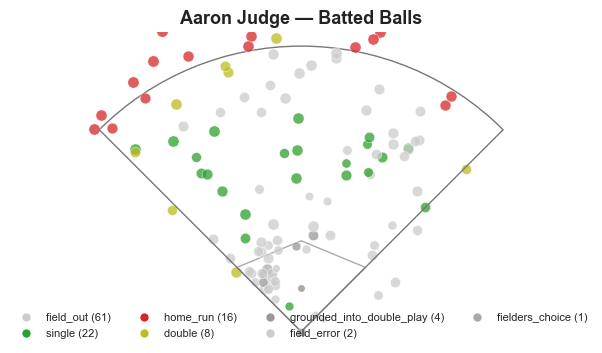

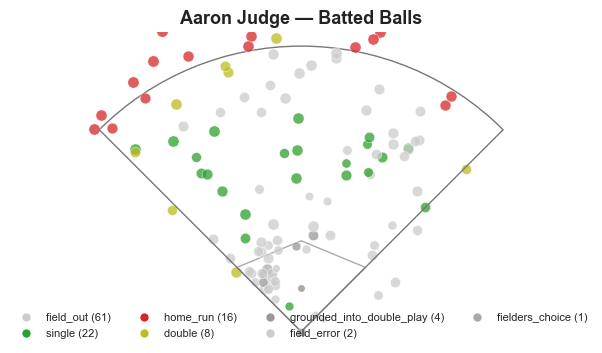

In [5]:
spray_chart(df, title=f'{player} — Batted Balls')


## §3 Zone Profile

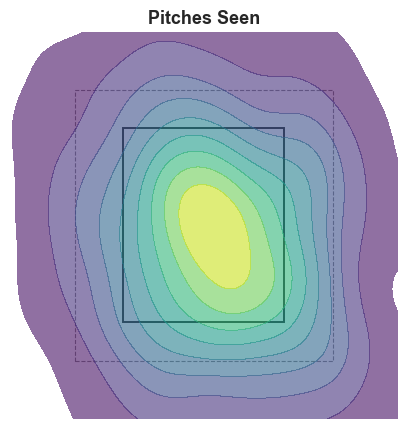

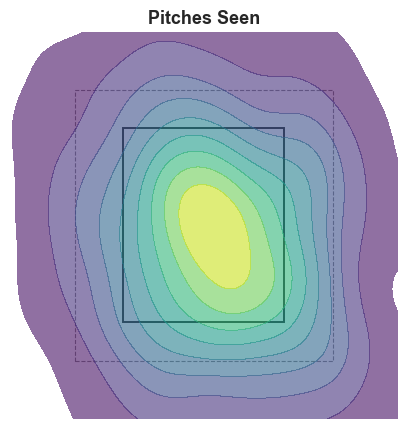

In [6]:
zone_heatmap(df, metric='density', title='Pitches Seen')


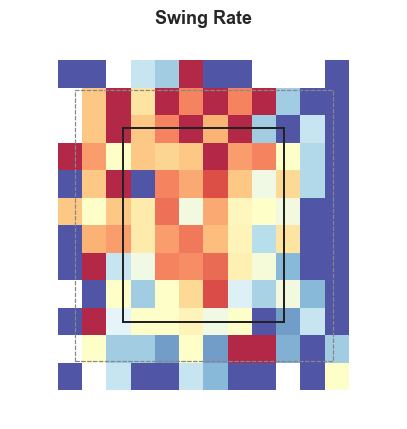

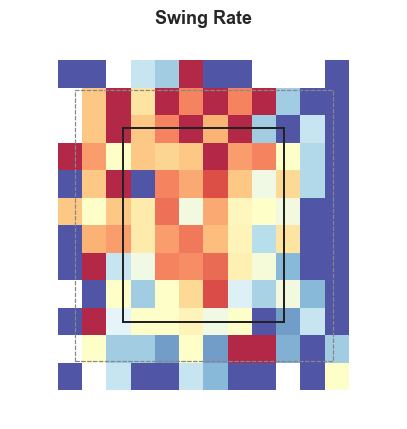

In [7]:
zone_heatmap(df, metric='swing_rate', title='Swing Rate')


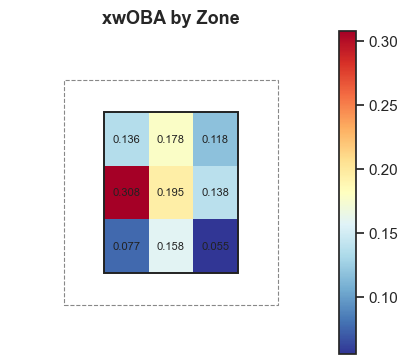

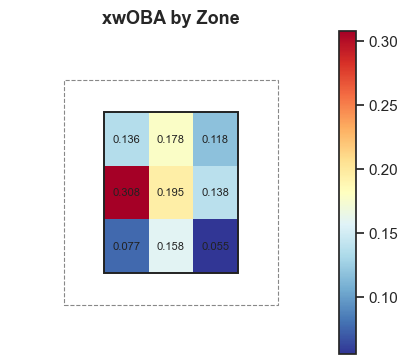

In [8]:
zone_grid(df, metric='xwoba', bins=3, title='xwOBA by Zone')


## §4 Contact Profile

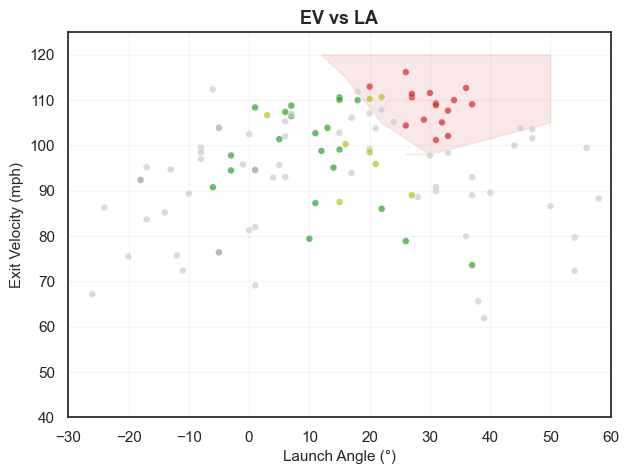

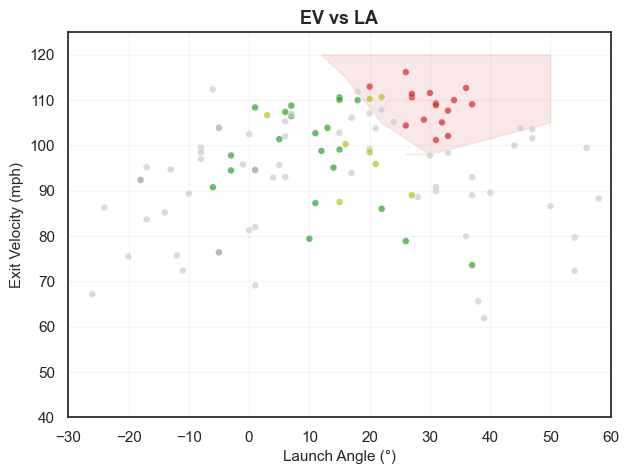

In [9]:
ev_la_scatter(df, color_by='outcome', overlay_barrel_zone=True, title='EV vs LA')


## §5 Splits

,PA,AB,H,1B,2B,3B,HR,BB,IBB,HBP,...,OBP,SLG,OPS,ISO,BB%,K%,BB/K,wOBA,xwOBA,xBA
vs_hand,,,,,,,,,,,,,,,,,,,,,
vs LHP,67.0,49.0,12.0,6.0,1.0,0.0,5.0,18.0,3.0,0.0,...,0.447761,0.571429,1.019190,0.326531,0.268657,0.238806,1.125000,0.457031,0.576061,0.435515
vs RHP,145.0,124.0,34.0,16.0,7.0,0.0,11.0,19.0,2.0,2.0,...,0.379310,0.596774,0.976085,0.322581,0.131034,0.282759,0.463415,0.436713,0.584284,0.420395


,PA,AB,H,1B,2B,3B,HR,BB,IBB,HBP,...,OBP,SLG,OPS,ISO,BB%,K%,BB/K,wOBA,xwOBA,xBA
home_away,,,,,,,,,,,,,,,,,,,,,
Home,98.0,82.0,24.0,11.0,4.0,0.0,9.0,15.0,3.0,1.0,...,0.408163,0.670732,1.078895,0.378049,0.153061,0.275510,0.555556,0.481053,0.636241,0.440648
Away,114.0,91.0,22.0,11.0,4.0,0.0,7.0,22.0,2.0,1.0,...,0.394737,0.516484,0.911220,0.274725,0.192982,0.263158,0.733333,0.410714,0.533000,0.410483


,PA,AB,H,1B,2B,3B,HR,BB,IBB,HBP,...,OBP,SLG,OPS,ISO,BB%,K%,BB/K,wOBA,xwOBA,xBA
month,,,,,,,,,,,,,,,,,,,,,
Mar,16.0,15.0,3.0,1.0,0.0,0.0,2.0,1.0,0.0,0.0,...,0.250000,0.600000,0.850000,0.400000,0.062500,0.375000,0.166667,0.350000,0.539889,0.361000
Apr,114.0,92.0,25.0,10.0,5.0,0.0,10.0,20.0,1.0,2.0,...,0.412281,0.652174,1.064455,0.380435,0.175439,0.236842,0.740741,0.467699,0.622531,0.437594
May,82.0,66.0,18.0,11.0,3.0,0.0,4.0,16.0,4.0,0.0,...,0.414634,0.500000,0.914634,0.227273,0.195122,0.292683,0.666667,0.426282,0.527707,0.418756


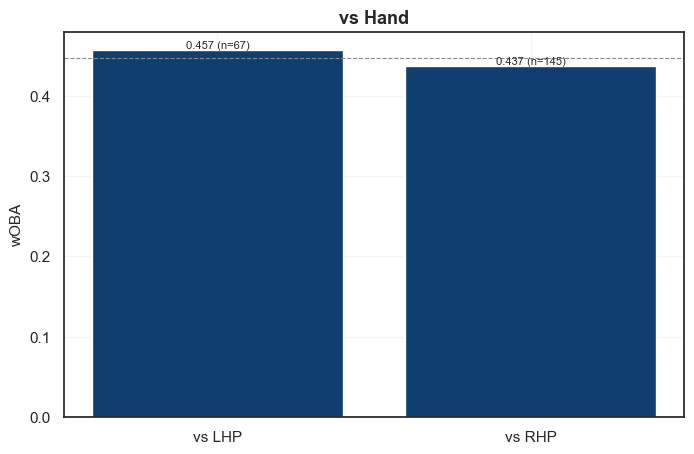

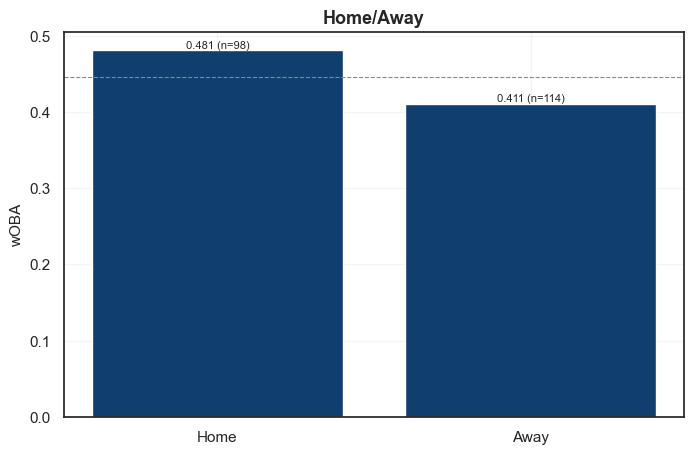

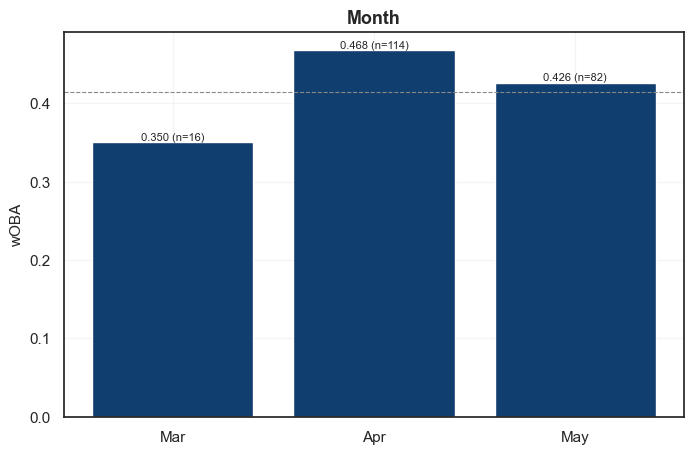

In [10]:
for axis, title in [('vs_hand','vs Hand'),('home_away','Home/Away'),('month','Month')]:
    s = batting_splits(df, axis=axis)
    display(s)
    splits_bar_chart(s, metric='wOBA', title=title)


## §6 Performance by Pitch Type

In [11]:
display(performance_by_pitch_type(df))


,Pitches,Whiff%,AVG,SLG,xwOBA,Avg EV,Avg LA
pitch_type,,,,,,,
FF,240,0.233010,0.272727,0.696970,0.634182,98.072727,27.090909
SL,153,0.409091,0.148148,0.296296,0.387294,91.870588,8.411765
SI,142,0.108696,0.458333,0.750000,0.627111,88.427778,-0.111111
CH,132,0.366667,0.142857,0.285714,0.390200,89.315000,7.100000
FC,77,0.351351,0.352941,0.588235,0.454556,91.422222,18.222222
CU,66,0.448276,0.214286,0.642857,0.816000,94.816667,20.333333
ST,66,0.200000,0.222222,0.500000,0.503533,96.993333,26.933333
FS,28,0.687500,0.375000,1.125000,1.255750,104.375000,19.500000
KC,6,0.000000,0.666667,2.666667,1.715333,109.766667,25.666667


## §7 Recent Form

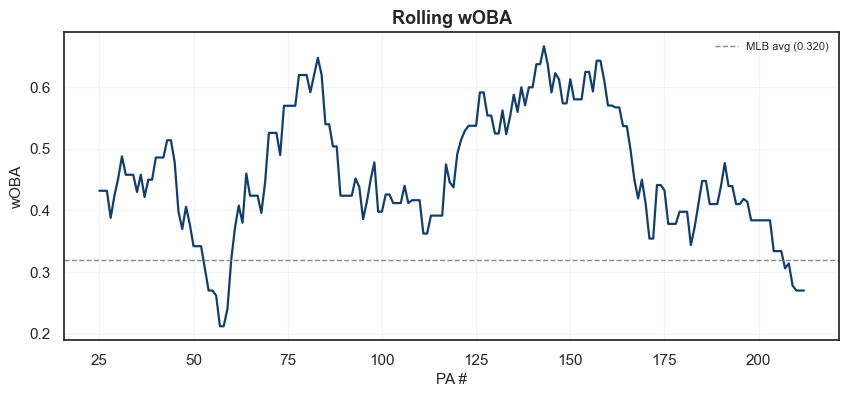

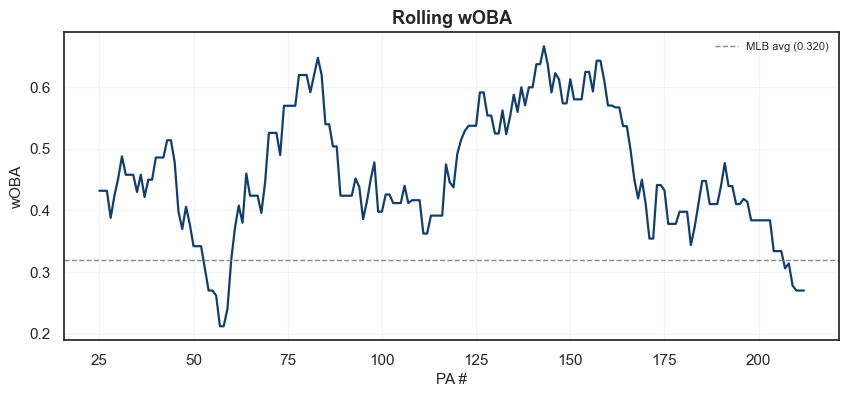

In [12]:
rolling = rolling_batting_line(df, window=recent_form_pas, over='PA')
rolling_metric_line(rolling, metric='wOBA', league_average=0.320, title='Rolling wOBA')


## §8 Takeaways

In [13]:
from mlb_stats_lab.reports.summary import batter_bullets
display(Markdown('\n'.join(batter_bullets(line, disc, contact))))


→ wOBA 0.443 — elite production tier.
→ ISO 0.324 — top-tier power.
→ BB% 17.5% — strong plate patience.
→ Whiff% 31.2% — swing-and-miss prone.
→ Barrel% 23.7% — premium contact quality.
→ HardHit% 55.3% — punishes mistakes.

## §9 Export to PDF (optional)

In [15]:
# Uncomment to render a PDF:
from mlb_stats_lab.reports import render_report, build_batter_profile_context
ctx = build_batter_profile_context({'player': player, 'season': season, 'start_date': start_date, 'end_date': end_date, 'recent_form_pas': recent_form_pas})
render_report('batter-profile', ctx, f'{player.replace(" ", "_")}__{end_date}.pdf')


PosixPath('/Users/rileygrotenhuis/rileyedward/mlb-stats-lab/reports/output/Aaron_Judge__2026-05-20.pdf')